# Exploratory Data Analysis

---

## 1. Importing Libraries

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

---

## 2. Loading data

In [2]:
df = pd.read_csv("../data/raw/student_performance.csv", sep=",")

In [3]:
df.shape

(1000000, 6)

---

## 3. Overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   student_id               1000000 non-null  int64  
 1   weekly_self_study_hours  1000000 non-null  float64
 2   attendance_percentage    1000000 non-null  float64
 3   class_participation      1000000 non-null  float64
 4   total_score              1000000 non-null  float64
 5   grade                    1000000 non-null  str    
dtypes: float64(4), int64(1), str(1)
memory usage: 45.8 MB


In [5]:
df.head(10)

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A
5,6,13.4,65.1,5.0,97.5,A
6,7,26.1,81.8,5.9,100.0,A
7,8,20.4,100.0,4.0,96.1,A
8,9,11.7,100.0,8.2,69.8,C
9,10,18.8,67.6,6.0,80.3,B


In [6]:
df.tail(10)

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
999990,999991,15.4,82.8,4.0,86.9,A
999991,999992,30.0,87.4,6.7,100.0,A
999992,999993,26.3,84.6,4.5,100.0,A
999993,999994,20.7,82.4,5.5,99.1,A
999994,999995,15.1,77.0,9.2,80.5,B
999995,999996,18.0,95.5,4.8,100.0,A
999996,999997,15.7,82.7,6.7,88.3,A
999997,999998,14.2,85.1,5.8,87.9,A
999998,999999,25.3,90.0,5.3,100.0,A
999999,1000000,18.3,84.6,4.1,100.0,A


---

## 4. Quality Checks

In [7]:
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

In [8]:
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    if not outliers.empty:
        print(f"Detected {len(outliers)} outliers  in '{column}'")

Detected 3541 outliers  in 'weekly_self_study_hours'
Detected 3518 outliers  in 'attendance_percentage'
Detected 4927 outliers  in 'class_participation'
Detected 2027 outliers  in 'total_score'


In [9]:
df.isna().sum()

student_id                 0
weekly_self_study_hours    0
attendance_percentage      0
class_participation        0
total_score                0
grade                      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

### Note

The dataset does not contain missing values or duplicate records, but there are outliers in some columns. We should use IQR method to detect and remove them.

## 5. Target

In [11]:
df["grade"].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
df["grade"].value_counts()

grade
A    548644
B    258174
C    141980
D     44998
F      6204
Name: count, dtype: int64

### ( ! ) Note

The dataset exhibits a severe class imbalance, which will be addressed in a later stage. Additionally, because the target variable is categorical, it must be encoded.

---

## 6. Features

In [13]:
df.drop(columns=["grade"]).dtypes

student_id                   int64
weekly_self_study_hours    float64
attendance_percentage      float64
class_participation        float64
total_score                float64
dtype: object

In [14]:
df.drop(columns=["grade"]).nunique()

student_id                 1000000
weekly_self_study_hours        401
attendance_percentage          501
class_participation            101
total_score                    824
dtype: int64

### Note

We should scale these numeric columns.

---

## 7. Visualizations

### 7.1 Correlation Matrix

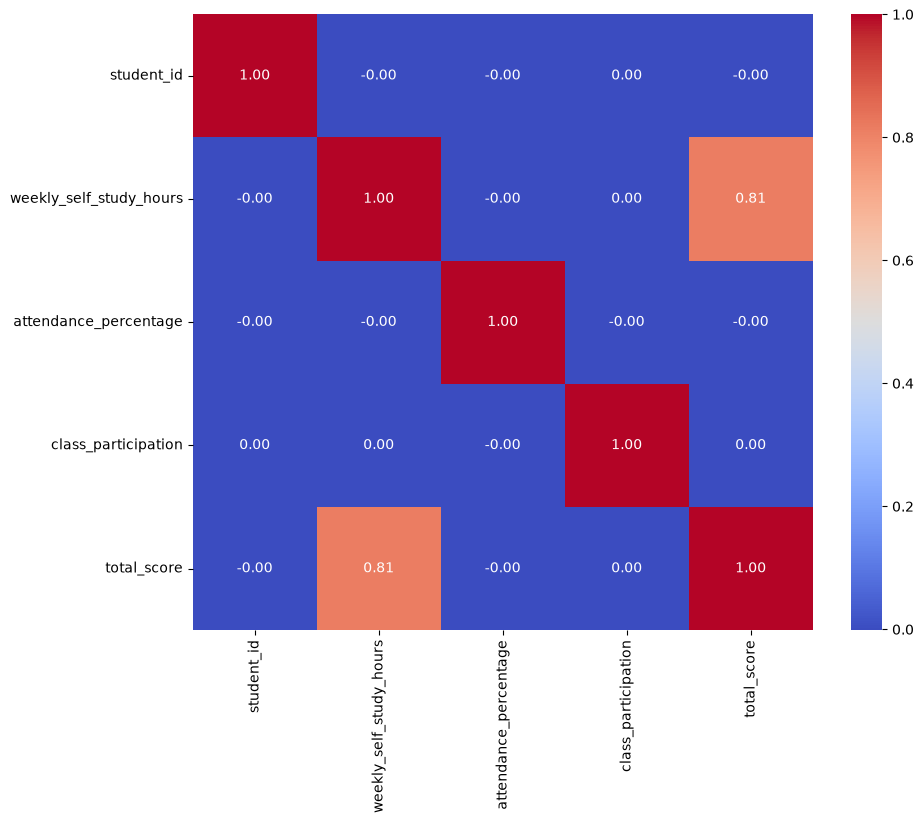

In [15]:
plt.figure(figsize=(10, 8), dpi=100)
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

This graph illustrates that `weekly_self_study_hours` is strongly correlated with the target.

### 7.2 Target Classes

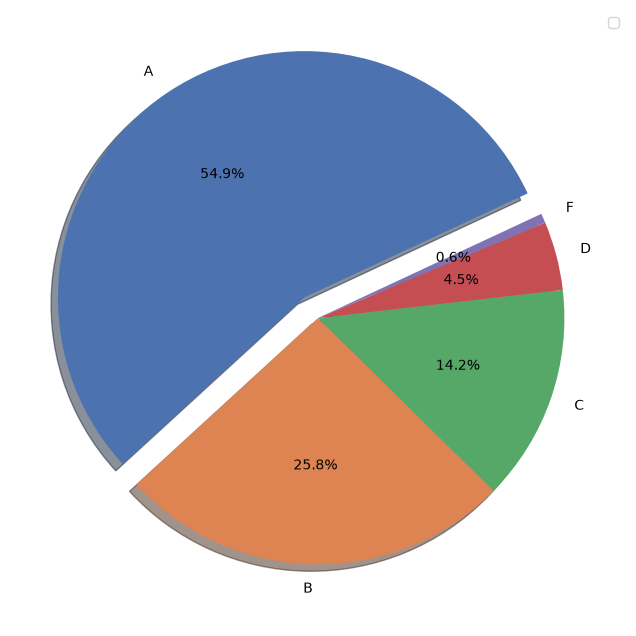

In [16]:
explode = (0.1, 0, 0, 0, 0)
colors = sns.palettes.color_palette("deep")

plt.figure(figsize=(10, 8), dpi=100)
plt.legend(["A", "B", "C", "D", "F"])
plt.pie(
    df["grade"].value_counts(),
    labels=df["grade"].value_counts().index,
    colors=colors,
    autopct="%1.1f%%",
    shadow=True,
    startangle=25,
    explode=explode,
)
plt.show()

This graph illustrates the imbalance between classes.

### 7.3 Weekly Study Hours

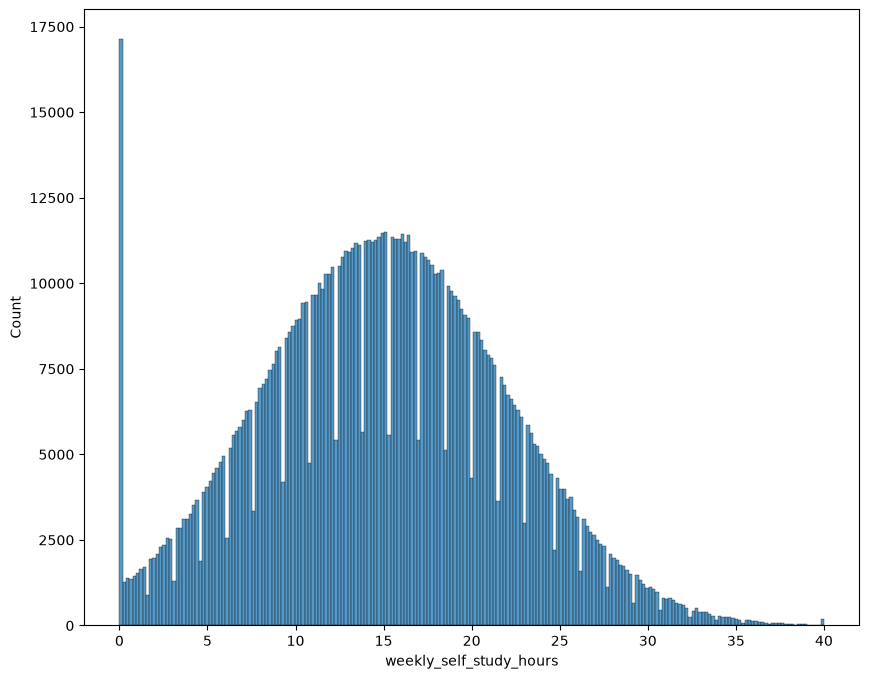

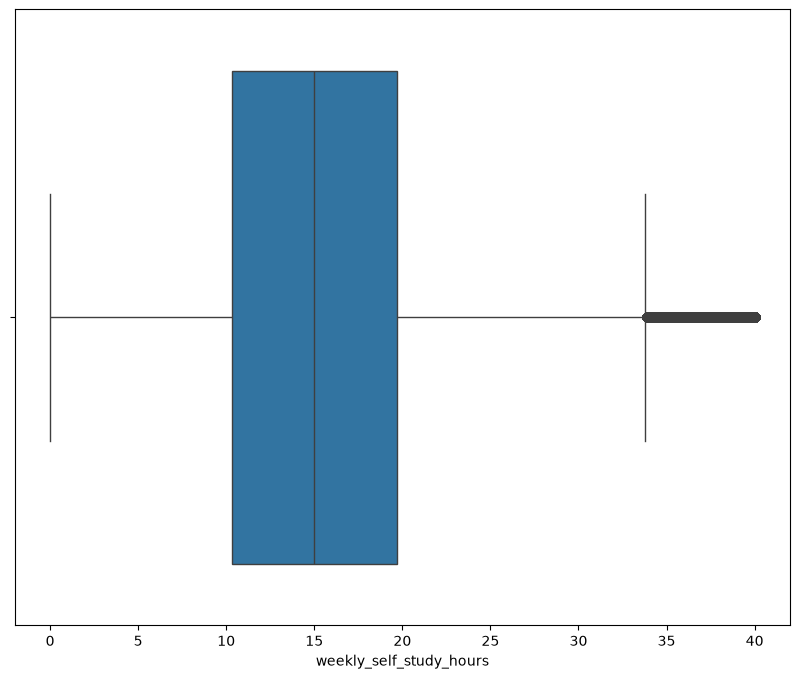

In [17]:
plt.figure(figsize=(10, 8), dpi=100)
sns.histplot(x=df["weekly_self_study_hours"])

plt.figure(figsize=(10, 8), dpi=100)
sns.boxplot(x=df["weekly_self_study_hours"])
plt.show()

A significant number of students failed to complete their self-study hours.

### 7.4 Attendance Percentage

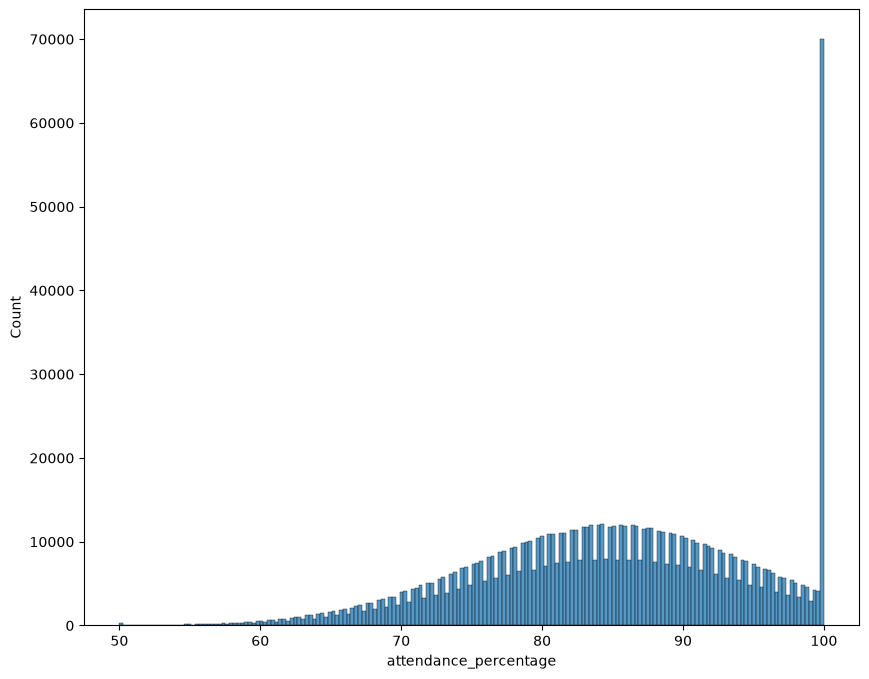

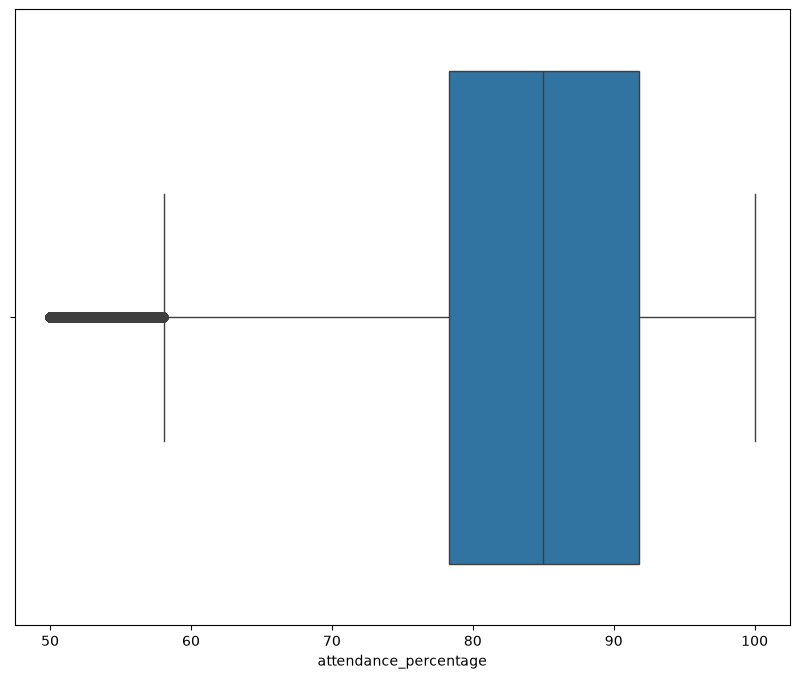

In [18]:
plt.figure(figsize=(10, 8), dpi=100)
sns.histplot(x=df["attendance_percentage"])

plt.figure(figsize=(10, 8), dpi=100)
sns.boxplot(x=df["attendance_percentage"])
plt.show()

### 7.5 Class Particiation

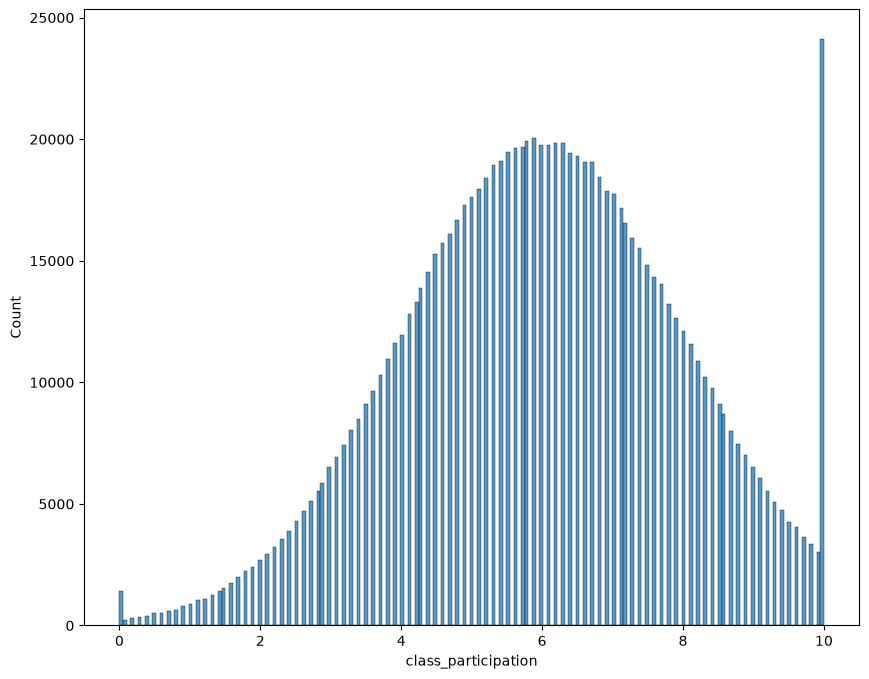

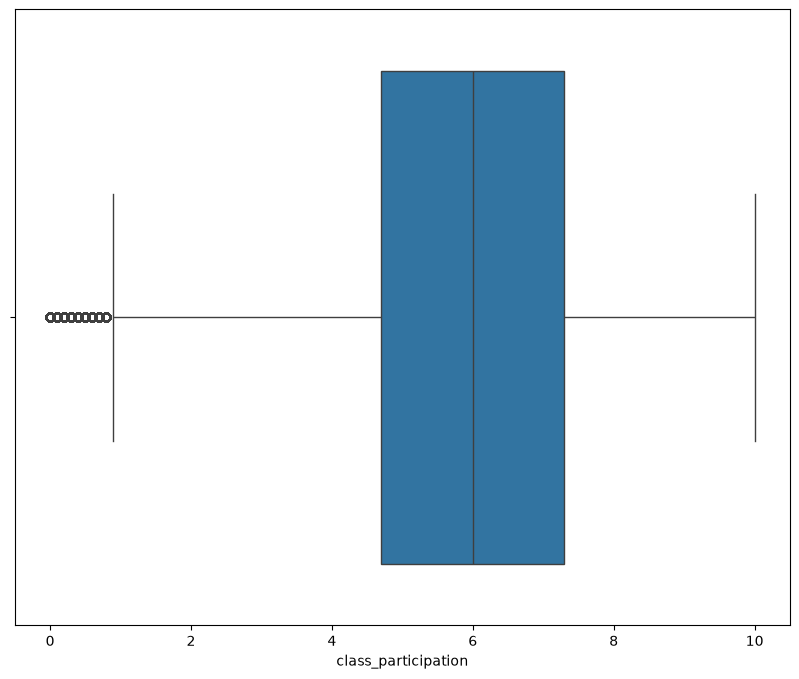

In [19]:
plt.figure(figsize=(10, 8), dpi=100)
sns.histplot(x=df["class_participation"])

plt.figure(figsize=(10, 8), dpi=100)
sns.boxplot(x=df["class_participation"])
plt.show()

A substantial majority of students participated in class.

---

# 8. Results

The dataset contains no missing values or entirely duplicate rows. However, duplicate records exist within specific columns. Additionally, the target classes are imbalanced. To address this, we will downsample the data so that each class matches the row count of the minority class `F`. Finally, we will encode the target classes and scale the numeric features.